# Практичні роботи 4–7

## Мініпроєкт «Порівняння класичних моделей класифікації»

**Дисципліна:** Розпізнавання образів та класичне машинне навчання
**Студент:** Святішенко Дмитро
**Група:** ІН-32/2
**Дата виконання:** 01.11.2026

### Мета роботи

Навчитися будувати відтворюваний конвеєр машинного навчання, застосовувати класичні алгоритми
класифікації, налаштовувати їхні основні гіперпараметри та коректно порівнювати моделі за однаковими
умовами без використання тестової вибірки для підбору рішень.

| Частина | Практична робота | Зміст |
|---|---|---|
| I | 4 | підготовка даних, Pipeline, логістична регресія |
| II | 5 | k-NN, Gaussian Naive Bayes, LDA та QDA |
| III | 6 | лінійна SVM, RBF-SVM і пошук гіперпараметрів |
| IV | 7 | порівняння за CV, вибір фінальної моделі, одноразове тестування, збереження Pipeline |

> **Етичне застереження.** Результати цього навчального мініпроєкту не є медичним діагнозом
> і не повинні використовуватися для клінічних рішень.

## Постановка задачі

- **Об'єкт дослідження** — пацієнти клініки Cleveland (набір Heart Disease, UCI Machine Learning Repository, 303 записи).
- **Ознаки** — 13 характеристик пацієнта: вік, стать, тип болю в грудях, тиск у стані спокою, холестерин,
  рівень цукру натще, результати ЕКГ, максимальний пульс, стенокардія під час навантаження, депресія ST,
  нахил сегмента ST, кількість уражених судин і результат таліевого тесту.
- **Цільова змінна** — `target`: 0 — ознаки серцевого захворювання відсутні, 1 — наявні
  (початкові значення `num` = 1–4 об'єднано в клас 1).
- **Кількість класів** — 2 (бінарна класифікація з навчанням за розміченими даними).
- **Позитивний клас** — **1** (наявність ознак захворювання). Саме для нього обчислюються precision, recall і F1.
- **Практична мета** — за характеристиками пацієнта визначити, чи належить він до класу з наявністю
  ознак серцевого захворювання.
- **Основна метрика (обрана до початку експериментів)** — **F1-міра позитивного класу**. Додаткові:
  ROC AUC (якість ранжування) і recall (частка виявлених хворих — пропуск позитивного класу тут
  найнебезпечніший), допоміжні — precision, accuracy і час навчання.

### Правило вибору фінальної моделі (зафіксовано заздалегідь)

1. Для кожного алгоритму найкращу конфігурацію обираємо за найбільшим середнім **CV F1**
   (за рівності — за більшим CV ROC AUC, далі — простіша модель).
2. Серед найкращих конфігурацій алгоритмів у короткий список потрапляють моделі, чий CV F1 відстає
   від лідера не більше ніж на **0,01**.
3. З короткого списку обирається модель із меншим стандартним відхиленням CV F1 і більшим CV recall;
   за рівності — простіша й краще інтерпретована.
4. Тестова вибірка відкривається лише один раз — для вже зафіксованої фінальної моделі.

# ЧАСТИНА I. Практична робота 4

## Підготовка даних, Pipeline і логістична регресія

### 1. Підключення бібліотек

In [1]:
from pathlib import Path
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC

from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

Python: 3.12.11
pandas: 3.0.6
scikit-learn: 1.9.1
joblib: 1.6.0


### 2. Підключення Google Drive і шляхи проєкту

Мініпроєкт розміщено в папці `classification-mini-project/` репозиторію `pattern-recognition-practice`.
Поза Colab робочою папкою вважається корінь мініпроєкту (Notebook лежить у `notebooks/`).

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Notebook виконується поза Google Colab — використовується локальна папка проєкту.")

Notebook виконується поза Google Colab — використовується локальна папка проєкту.


In [4]:
if IN_COLAB:
    PROJECT_DIR = Path(
        "/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project"
    )
else:
    PROJECT_DIR = Path.cwd().parent

DATA_PATH = PROJECT_DIR / "data" / "heart_disease.csv"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

MODEL_PATH = MODELS_DIR / "best_classifier.joblib"
CV_COMPARISON_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_METRICS_PATH = REPORTS_DIR / "final_test_metrics.csv"

for folder in (DATA_PATH.parent, MODELS_DIR, REPORTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Файл даних:", DATA_PATH.relative_to(PROJECT_DIR))
print("Файл моделі:", MODEL_PATH.relative_to(PROJECT_DIR))

Файл даних: data\heart_disease.csv
Файл моделі: models\best_classifier.joblib


### 3. Завантаження та первинна перевірка даних

Файл `heart_disease.csv` сформовано з `processed.cleveland.data` репозиторію UCI: стовпцям надано
назви, позначку пропуску `?` замінено на `NaN`, ціль `num` перетворено на бінарну `target`
(0 → 0, 1–4 → 1). Якщо файла немає, наступна комірка відтворює його з UCI тим самим способом.

На цьому етапі виконується лише аудит — жодних імпутацій, масштабування чи кодування на всьому наборі.

In [5]:
UCI_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)
COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

if not DATA_PATH.exists():
    raw = pd.read_csv(UCI_URL, header=None, names=COLUMNS, na_values="?")
    raw["target"] = (raw.pop("num") > 0).astype(int)
    raw.to_csv(DATA_PATH, index=False)
    print("Файл створено з UCI:", DATA_PATH.name)

data = pd.read_csv(DATA_PATH)

display(data.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [6]:
print("Розмір таблиці:", data.shape)
print("\nТипи даних:")
print(data.dtypes)

Розмір таблиці: (303, 14)

Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


In [7]:
missing = data.isna().sum()
print("Пропущені значення за стовпцями:")
print(missing[missing > 0])
print("\nУсього пропусків:", int(missing.sum()))
print("Рядків із пропусками:", int(data.isna().any(axis=1).sum()))
print("Повних дублікатів:", int(data.duplicated().sum()))

Пропущені значення за стовпцями:
ca      4
thal    2
dtype: int64

Усього пропусків: 6
Рядків із пропусками: 6
Повних дублікатів: 0


In [8]:
TARGET = "target"
POSITIVE_CLASS = 1

print("Допустимі значення target:", sorted(data[TARGET].unique().tolist()))
assert set(data[TARGET].unique()) == {0, 1}, "target має містити лише 0 і 1"

class_counts = pd.DataFrame(
    {
        "count": data[TARGET].value_counts().sort_index(),
        "percent": data[TARGET].value_counts(normalize=True).sort_index().mul(100).round(2)
    }
)
class_counts.index = ["0 – ознак немає", "1 – ознаки наявні"]
display(class_counts)

Допустимі значення target: [0, 1]


,count,percent
0 – ознак немає,164,54.13
1 – ознаки наявні,139,45.87


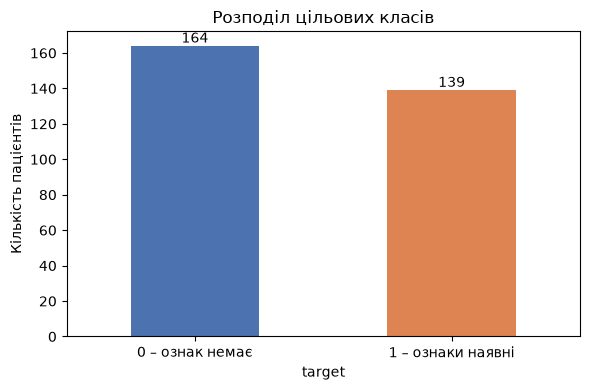

In [9]:
ax = data[TARGET].value_counts().sort_index().plot(
    kind="bar", color=["#4C72B0", "#DD8452"], figsize=(6, 4)
)
ax.set_xticklabels(["0 – ознак немає", "1 – ознаки наявні"], rotation=0)
ax.set_ylabel("Кількість пацієнтів")
ax.set_title("Розподіл цільових класів")
for patch in ax.patches:
    ax.annotate(int(patch.get_height()),
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "pr04_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

#### Типи ознак

У файлі частина категоріальних ознак збережена числовими кодами, тому тип `int`/`float` у pandas
не означає, що ознака кількісна. Наприклад, `cp` = 1, 2, 3, 4 — коди типу болю, а не шкала,
тому до неї застосовується OneHotEncoder, а не StandardScaler.

In [10]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

assert set(numeric_columns + categorical_columns + [TARGET]) == set(data.columns)

print("Унікальні значення категоріальних ознак:")
for column in categorical_columns:
    values = sorted(data[column].dropna().unique().tolist())
    print(f"  {column:8s} {values}")

display(data[numeric_columns].describe().round(2))

Унікальні значення категоріальних ознак:
  sex      [0, 1]
  cp       [1, 2, 3, 4]
  fbs      [0, 1]
  restecg  [0, 1, 2]
  exang    [0, 1]
  slope    [1, 2, 3]
  ca       [0.0, 1.0, 2.0, 3.0]
  thal     [3.0, 6.0, 7.0]


,age,trestbps,chol,thalach,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


In [11]:
audit = pd.DataFrame(
    {
        "Характеристика": [
            "Кількість об'єктів",
            "Кількість вхідних ознак",
            "Числові ознаки",
            "Категоріальні ознаки",
            "Кількість пропусків",
            "Кількість класів",
            "Позитивний клас"
        ],
        "Значення": [
            data.shape[0],
            data.shape[1] - 1,
            ", ".join(numeric_columns),
            ", ".join(categorical_columns),
            f"{int(missing.sum())} (ca – {int(missing['ca'])}, thal – {int(missing['thal'])})",
            data[TARGET].nunique(),
            f"{POSITIVE_CLASS} – ознаки захворювання наявні"
        ]
    }
)
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,"6 (ca – 4, thal – 2)"
5,Кількість класів,2
6,Позитивний клас,1 – ознаки захворювання наявні


**Результат аудиту.** Набір містить **303 об'єкти** і **13 вхідних ознак** (5 числових і 8 категоріальних).
Є **6 пропусків**: 4 у `ca` і 2 у `thal` (6 рядків); дублікатів немає. Класи майже збалансовані:
164 пацієнти без ознак захворювання (54,13 %) і 139 з ознаками (45,87 %). Ціль містить лише 0 і 1.
Числові ознаки мають дуже різні діапазони (`chol` — сотні, `oldpeak` — одиниці), що важливо для
моделей, чутливих до масштабу. Дані придатні до побудови моделей; пропуски буде заповнено всередині Pipeline.